# Modelado predictivo de la rotación de inventario en Alkomprar

## Herramientas de Inteligencia Artificial y Ciencia de Datos

**Caso de estudio:** Alkomprar

**Estudiante:** Cristian Julian Vega Florez

**Programa:** Tecnología en Análisis y Gestión de Datos

**Universidad:** Universidad Tecnológica de Santander (UTS)

### Objetivo

Desarrollar un modelo de aprendizaje automático supervisado que permita analizar y predecir la rotación del inventario de los productos de Alkomprar a partir de variables relacionadas con precios, ventas, inventario, devoluciones, logística y características de los productos.


# 1. Importación de librerías

In [1]:
# Importamos las librerías necesarias para realizar el análisis
#En este bloque se importan las librerías necesarias para manipular
#los datos, realizar visualizaciones,
#preparar las variables y construir el
#modelo de aprendizaje automático.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Librerías para construir y evaluar el modelo
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Modelo de regresión
from sklearn.linear_model import LinearRegression

# Métricas de evaluación
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


# 2. Carga del conjunto de datos

In [2]:
# Cargamos el archivo CSV

# En Git/Jupyter local se lee desde data/raw. En Google Colab se puede
# cargar el CSV en el panel de archivos o ajustar esta ruta.
from pathlib import Path
ruta_datos = Path('../data/raw/alkomprar_datos_inventados.csv')
if not ruta_datos.exists():
    ruta_datos = Path('/content/alkomprar_datos_inventados.csv')
df = pd.read_csv(ruta_datos)

# Mostramos las primeras filas
df.head()

,ID_Producto,Categoria,Marca,Precio_Venta,Precio_Competencia,Unidades_Vendidas,Stock_Disponible,Unidades_Devueltas,Costo_Operativo,Tiempo_Entrega,...,Devolucion,Nivel_Satisfaccion,Motivo_Devolucion,Temporada,Canal_Venta,Proveedor,Diferencia_Precio,Tasa_Devolucion,Rotacion_Inventario,Dias_Inventario
0,ALK-0001,Hogar,Samsung,4234639,254356,168,141,10,561656,11,...,No,Medio,Entrega tardia,Regreso a clases,App,Proveedor D,3980283,0.059524,1.191489,306.339286
1,ALK-0002,Computacion,Motorola,2808130,3209320,151,193,7,208014,6,...,No,Alto,Producto diferente,Normal,Tienda fisica,Proveedor B,-401190,0.046358,0.782383,466.523179
2,ALK-0003,Audio,Haceb,3794515,465612,24,34,18,111751,2,...,No,Medio,Sin novedad,Regreso a clases,Tienda fisica,Proveedor A,3328903,0.750000,0.705882,517.083333
3,ALK-0004,Computacion,Samsung,1699159,3710333,150,204,12,250203,5,...,No,Alto,Entrega tardia,Black Friday,App,Proveedor D,-2011174,0.080000,0.735294,496.400000
4,ALK-0005,Computacion,Samsung,1027317,119435,51,105,11,231951,10,...,Si,Bajo,Cambio de opinion,Navidad,Pagina web,Proveedor C,907882,0.215686,0.485714,751.470588


# 3. Exploración inicial de los datos

In [3]:
# Visualizamos los primeros cinco registros

df.head()

,ID_Producto,Categoria,Marca,Precio_Venta,Precio_Competencia,Unidades_Vendidas,Stock_Disponible,Unidades_Devueltas,Costo_Operativo,Tiempo_Entrega,...,Devolucion,Nivel_Satisfaccion,Motivo_Devolucion,Temporada,Canal_Venta,Proveedor,Diferencia_Precio,Tasa_Devolucion,Rotacion_Inventario,Dias_Inventario
0,ALK-0001,Hogar,Samsung,4234639,254356,168,141,10,561656,11,...,No,Medio,Entrega tardia,Regreso a clases,App,Proveedor D,3980283,0.059524,1.191489,306.339286
1,ALK-0002,Computacion,Motorola,2808130,3209320,151,193,7,208014,6,...,No,Alto,Producto diferente,Normal,Tienda fisica,Proveedor B,-401190,0.046358,0.782383,466.523179
2,ALK-0003,Audio,Haceb,3794515,465612,24,34,18,111751,2,...,No,Medio,Sin novedad,Regreso a clases,Tienda fisica,Proveedor A,3328903,0.750000,0.705882,517.083333
3,ALK-0004,Computacion,Samsung,1699159,3710333,150,204,12,250203,5,...,No,Alto,Entrega tardia,Black Friday,App,Proveedor D,-2011174,0.080000,0.735294,496.400000
4,ALK-0005,Computacion,Samsung,1027317,119435,51,105,11,231951,10,...,Si,Bajo,Cambio de opinion,Navidad,Pagina web,Proveedor C,907882,0.215686,0.485714,751.470588


In [4]:
# Generamos estadísticas descriptivas de las variables numéricas

df.describe()

,Precio_Venta,Precio_Competencia,Unidades_Vendidas,Stock_Disponible,Unidades_Devueltas,Costo_Operativo,Tiempo_Entrega,Diferencia_Precio,Tasa_Devolucion,Rotacion_Inventario,Dias_Inventario
count,1.500000e+02,1.500000e+02,150.000000,150.000000,150.000000,150.000000,150.000000,1.500000e+02,150.000000,150.000000,150.000000
mean,2.381136e+06,2.391036e+06,90.206667,102.013333,8.573333,296847.833333,6.220000,-9.899847e+03,0.208090,1.545660,886.776714
std,1.295531e+06,1.270294e+06,49.881914,59.820423,5.717448,165530.307769,3.264349,1.831611e+06,0.432377,2.003148,1674.156385
min,2.352940e+05,1.194350e+05,5.000000,10.000000,0.000000,20126.000000,1.000000,-3.884605e+06,0.000000,0.026738,28.627451
25%,1.252486e+06,1.351616e+06,51.000000,49.500000,4.000000,165526.500000,3.000000,-1.317093e+06,0.042382,0.477986,223.541667
50%,2.370351e+06,2.412982e+06,89.500000,101.500000,8.000000,276861.000000,6.000000,1.657250e+04,0.100682,0.967005,377.456785
75%,3.475965e+06,3.472812e+06,136.000000,146.750000,13.000000,446323.250000,9.000000,1.116189e+06,0.173246,1.632828,763.686613
max,4.498727e+06,4.383085e+06,177.000000,219.000000,19.000000,596775.000000,11.000000,4.262474e+06,3.800000,12.750000,13651.000000


In [5]:
# Mostramos las columnas disponibles

print("Variables del conjunto de datos:")
for columna in df.columns:
    print("-", columna)

Variables del conjunto de datos:
- ID_Producto
- Categoria
- Marca
- Precio_Venta
- Precio_Competencia
- Unidades_Vendidas
- Stock_Disponible
- Unidades_Devueltas
- Costo_Operativo
- Tiempo_Entrega
- Promocion
- Devolucion
- Nivel_Satisfaccion
- Motivo_Devolucion
- Temporada
- Canal_Venta
- Proveedor
- Diferencia_Precio
- Tasa_Devolucion
- Rotacion_Inventario
- Dias_Inventario


# 4. Limpieza y preparación de los datos

In [7]:
# Revisamos cuántos valores nulos existen en cada variable

nulos = df.isnull().sum()

print(nulos)

ID_Producto            0
Categoria              0
Marca                  0
Precio_Venta           0
Precio_Competencia     0
Unidades_Vendidas      0
Stock_Disponible       0
Unidades_Devueltas     0
Costo_Operativo        0
Tiempo_Entrega         0
Promocion              0
Devolucion             0
Nivel_Satisfaccion     0
Motivo_Devolucion      0
Temporada              0
Canal_Venta            0
Proveedor              0
Diferencia_Precio      0
Tasa_Devolucion        0
Rotacion_Inventario    0
Dias_Inventario        0
dtype: int64


In [8]:
# Comprobamos si existen valores nulos en todo el conjunto

print("Total de valores nulos:", df.isnull().sum().sum())

Total de valores nulos: 0


In [9]:
# Revisamos si existen registros duplicados

duplicados = df.duplicated().sum()

print("Número de registros duplicados:", duplicados)

Número de registros duplicados: 0


In [10]:
# Mostramos los tipos de datos de cada variable

print(df.dtypes)

ID_Producto             object
Categoria               object
Marca                   object
Precio_Venta             int64
Precio_Competencia       int64
Unidades_Vendidas        int64
Stock_Disponible         int64
Unidades_Devueltas       int64
Costo_Operativo          int64
Tiempo_Entrega           int64
Promocion               object
Devolucion              object
Nivel_Satisfaccion      object
Motivo_Devolucion       object
Temporada               object
Canal_Venta             object
Proveedor               object
Diferencia_Precio        int64
Tasa_Devolucion        float64
Rotacion_Inventario    float64
Dias_Inventario        float64
dtype: object


# 5. Selección de variables predictoras y variable objetivo

In [12]:
# Definimos la variable objetivo

y = df['Unidades_Vendidas']

# Seleccionamos las variables predictoras
# No incluimos ID_Producto porque funciona únicamente como identificador

X = df.drop(columns=['Unidades_Vendidas', 'ID_Producto'])

print("Variables predictoras:")
print(X.columns.tolist())

print("\nVariable objetivo:")
print(y.name)

Variables predictoras:
['Categoria', 'Marca', 'Precio_Venta', 'Precio_Competencia', 'Stock_Disponible', 'Unidades_Devueltas', 'Costo_Operativo', 'Tiempo_Entrega', 'Promocion', 'Devolucion', 'Nivel_Satisfaccion', 'Motivo_Devolucion', 'Temporada', 'Canal_Venta', 'Proveedor', 'Diferencia_Precio', 'Tasa_Devolucion', 'Rotacion_Inventario', 'Dias_Inventario']

Variable objetivo:
Unidades_Vendidas


In [13]:
# Identificamos las variables numéricas

variables_numericas = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Identificamos las variables categóricas

variables_categoricas = X.select_dtypes(
    include=['object']
).columns.tolist()

print("Variables numéricas:")
print(variables_numericas)

print("\nVariables categóricas:")
print(variables_categoricas)

Variables numéricas:
['Precio_Venta', 'Precio_Competencia', 'Stock_Disponible', 'Unidades_Devueltas', 'Costo_Operativo', 'Tiempo_Entrega', 'Diferencia_Precio', 'Tasa_Devolucion', 'Rotacion_Inventario', 'Dias_Inventario']

Variables categóricas:
['Categoria', 'Marca', 'Promocion', 'Devolucion', 'Nivel_Satisfaccion', 'Motivo_Devolucion', 'Temporada', 'Canal_Venta', 'Proveedor']


# 6. División del conjunto de datos

In [14]:
# Dividimos los datos en entrenamiento y prueba
# Utilizamos 80% para entrenamiento y 20% para prueba

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Datos de entrenamiento:", X_train.shape)
print("Datos de prueba:", X_test.shape)

Datos de entrenamiento: (120, 19)
Datos de prueba: (30, 19)


In [15]:
# Creamos un transformador para las variables categóricas.
# OneHotEncoder convierte las categorías en variables numéricas.

preprocesamiento = ColumnTransformer(
    transformers=[
        (
            'categoricas',
            OneHotEncoder(handle_unknown='ignore'),
            variables_categoricas
        )
    ],
    remainder='passthrough'
)

In [16]:
# Creamos el modelo de regresión lineal

modelo_regresion = LinearRegression()

In [17]:
# Construimos un pipeline que primero prepara los datos
# y después entrena el modelo de regresión lineal.

modelo = Pipeline(
    steps=[
        ('preprocesamiento', preprocesamiento),
        ('regresion', modelo_regresion)
    ]
)

# 7. Entrenamiento del modelo

In [18]:
# Entrenamos el modelo utilizando únicamente los datos de entrenamiento

modelo.fit(X_train, y_train)

print("Modelo entrenado correctamente.")

Modelo entrenado correctamente.


In [19]:
# Utilizamos el modelo entrenado para realizar predicciones
# sobre los datos que fueron reservados para prueba.

y_pred = modelo.predict(X_test)

# Mostramos algunas predicciones

print("Primeras predicciones:")
print(y_pred[:10])

Primeras predicciones:
[ 74.32015538 128.46445817 147.4284292  113.76727889  87.08132879
  84.38326195  93.86307578 129.02277549   5.67974655  87.02542793]


# 8. Evaluación del modelo

In [20]:
# Calculamos las métricas de evaluación

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 36.20577398760318
MSE: 2967.7389029100627
RMSE: 54.476957540872846
R²: -0.8374967151093304


In [21]:
# Creamos una tabla para resumir las métricas obtenidas

resultados = pd.DataFrame({
    'Métrica': ['MAE', 'MSE', 'RMSE', 'R²'],
    'Resultado': [mae, mse, rmse, r2]
})

resultados

,Métrica,Resultado
0,MAE,36.205774
1,MSE,2967.738903
2,RMSE,54.476958
3,R²,-0.837497


In [22]:
# Creamos una tabla comparando las unidades realmente vendidas
# con las unidades estimadas por el modelo.

comparacion = pd.DataFrame({
    'Real': y_test.values,
    'Prediccion': y_pred
})

comparacion.head(10)

,Real,Prediccion
0,27,74.320155
1,106,128.464458
2,95,147.428429
3,89,113.767279
4,87,87.081329
5,45,84.383262
6,103,93.863076
7,115,129.022775
8,10,5.679747
9,55,87.025428


# 9. Visualización de resultados

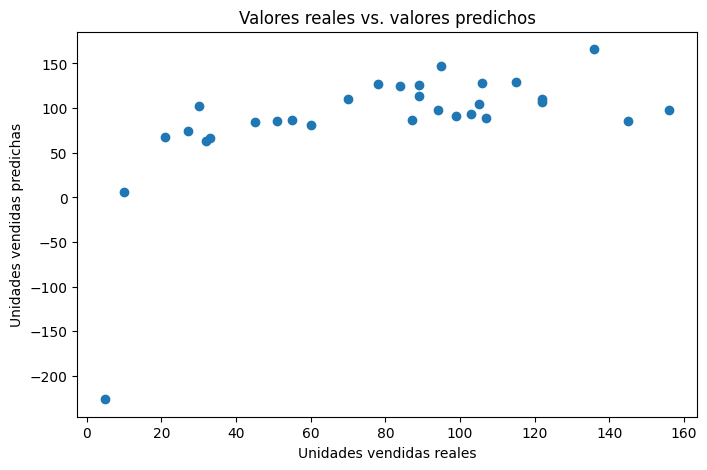

In [23]:
# Graficamos los valores reales frente a los valores predichos

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel('Unidades vendidas reales')
plt.ylabel('Unidades vendidas predichas')

plt.title('Valores reales vs. valores predichos')

plt.show()

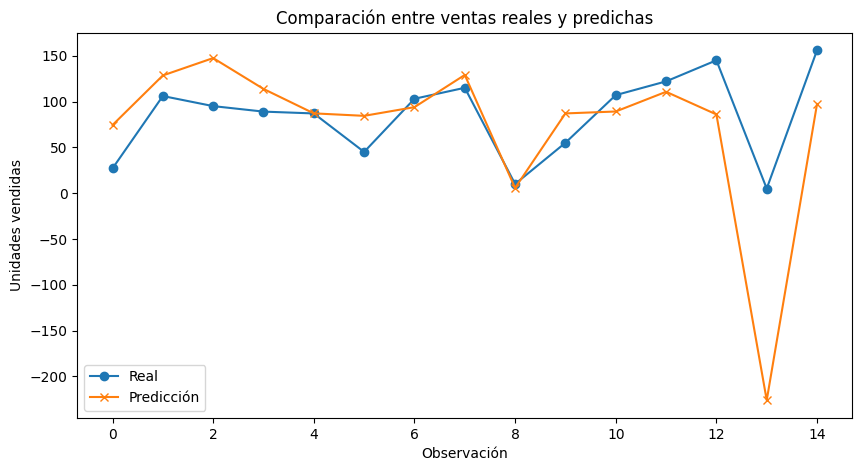

In [24]:
# Seleccionamos las primeras observaciones para comparar
# los valores reales con las predicciones.

comparacion_grafica = comparacion.head(15)

plt.figure(figsize=(10, 5))

plt.plot(
    range(len(comparacion_grafica)),
    comparacion_grafica['Real'],
    marker='o',
    label='Real'
)

plt.plot(
    range(len(comparacion_grafica)),
    comparacion_grafica['Prediccion'],
    marker='x',
    label='Predicción'
)

plt.xlabel('Observación')
plt.ylabel('Unidades vendidas')

plt.title('Comparación entre ventas reales y predichas')

plt.legend()

plt.show()

# 10. Reflexión final
El modelo de regresión lineal permitió analizar la relación existente entre diferentes características de los productos y las unidades vendidas. Para su construcción se utilizaron variables relacionadas con precio, competencia, inventario, devoluciones, promoción, categoría, marca, temporada y canal de venta.

La división del conjunto de datos permitió entrenar el modelo con el 80 % de las observaciones y evaluar su desempeño con el 20 % restante. Las métricas MAE, MSE, RMSE y R² permitieron determinar el nivel de error y la capacidad explicativa del modelo.

Sin embargo, el modelo presenta algunas limitaciones. El conjunto de datos contiene solamente 150 registros y corresponde a datos simulados, por lo que los resultados no deben interpretarse como una representación exacta del comportamiento comercial real.
